# Outcome vs Uncertainty Explorer

Plots any scalar outcome against any uncertainty or lever from multi-run results.

Default: **T1 BCAS death rate** vs **waves per day**, with boxplots showing
the distribution of death rates at each discrete uncertainty level.

In [11]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

FOLDER_NAME = "20260527_195058_scenario_1ccp_1btg"
run_folder = paths.MULTI_RUN_OUTPUT / FOLDER_NAME

df = pd.read_csv(run_folder / "results.csv")
print(f"Loaded {len(df)} runs  |  {df.shape[1]} columns")
print(f"Scenarios: {df['scenario'].nunique()}  |  Policies: {df['policy'].nunique()}")

Loaded 810 runs  |  153 columns
Scenarios: 27  |  Policies: 30


## Configure what to plot

Change `OUTCOME` and `UNCERTAINTY` to explore different combinations.
The cell below lists all available columns for reference.

In [12]:
# ── What to plot ─────────────────────────────────────────────────────────────
OUTCOME     = "death_rate_T1_BCAS"
UNCERTAINTY = "waves_per_day"

# ── Labels (auto-derived, override if needed) ────────────────────────────────
outcome_label     = OUTCOME.replace("_", " ").title()
uncertainty_label = UNCERTAINTY.replace("_", " ").title()

assert OUTCOME in df.columns,     f"{OUTCOME} not found. Available: {[c for c in df.columns if not c.startswith(('scenario','policy','model'))]}"
assert UNCERTAINTY in df.columns,  f"{UNCERTAINTY} not found."
print(f"Plotting: {OUTCOME} vs {UNCERTAINTY}")

Plotting: death_rate_T1_BCAS vs waves_per_day


## Boxplot — outcome distribution at each uncertainty level

C:\Users\User\AppData\Local\Temp\ipykernel_9928\3878530046.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)


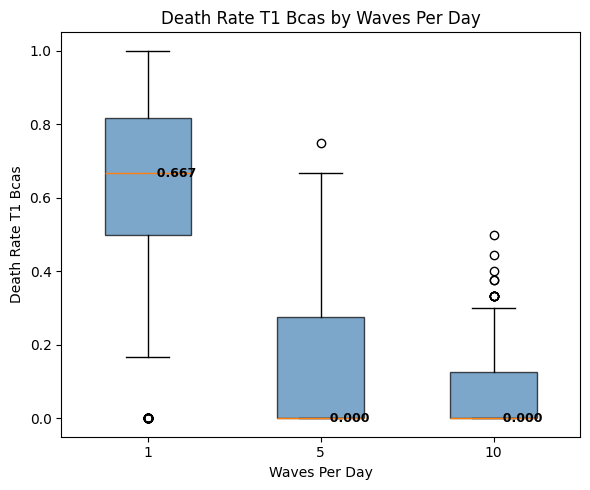

                 n   mean  median    std    min    max
waves_per_day                                         
1              270 0.6069  0.6667 0.3080 0.0000 1.0000
5              270 0.1454  0.0000 0.1876 0.0000 0.7500
10             270 0.0601  0.0000 0.1061 0.0000 0.5000


In [13]:
levels = sorted(df[UNCERTAINTY].dropna().unique())
data = [df.loc[df[UNCERTAINTY] == lv, OUTCOME].dropna().values for lv in levels]

fig, ax = plt.subplots(figsize=(max(6, len(levels) * 1.5), 5))
bp = ax.boxplot(data, labels=[str(lv) for lv in levels], patch_artist=True, widths=0.5)
for patch in bp["boxes"]:
    patch.set_facecolor("steelblue")
    patch.set_alpha(0.7)

# Annotate medians
for i, d in enumerate(data):
    med = np.median(d)
    ax.text(i + 1, med, f"  {med:.3f}", va="center", fontsize=9, fontweight="bold")

ax.set_xlabel(uncertainty_label)
ax.set_ylabel(outcome_label)
ax.set_title(f"{outcome_label} by {uncertainty_label}")
plt.tight_layout()
plt.show()

# Summary table
summary = df.groupby(UNCERTAINTY)[OUTCOME].agg(["count", "mean", "median", "std", "min", "max"])
summary.columns = ["n", "mean", "median", "std", "min", "max"]
print(summary.to_string(float_format="%.4f"))

## Scatter with mean trend line

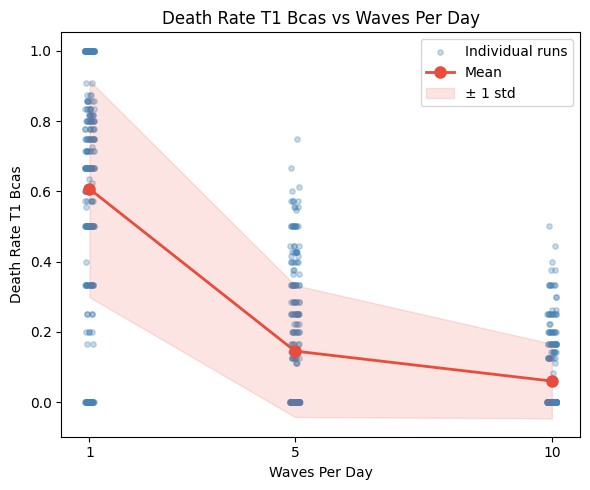

In [14]:
fig, ax = plt.subplots(figsize=(max(6, len(levels) * 1.5), 5))

# Jittered scatter of individual runs
jitter = (max(levels) - min(levels)) * 0.01 if len(levels) > 1 else 0.1
x_jit = df[UNCERTAINTY] + np.random.uniform(-jitter, jitter, size=len(df))
ax.scatter(x_jit, df[OUTCOME], alpha=0.3, s=15, color="steelblue", label="Individual runs")

# Mean ± std ribbon
means = df.groupby(UNCERTAINTY)[OUTCOME].mean()
stds  = df.groupby(UNCERTAINTY)[OUTCOME].std()
ax.plot(means.index, means.values, "o-", color="#e74c3c", linewidth=2, markersize=8, label="Mean", zorder=5)
ax.fill_between(means.index, means - stds, means + stds, alpha=0.15, color="#e74c3c", label="± 1 std")

ax.set_xlabel(uncertainty_label)
ax.set_ylabel(outcome_label)
ax.set_title(f"{outcome_label} vs {uncertainty_label}")
ax.set_xticks(levels)
ax.legend()
plt.tight_layout()
plt.show()

## Heatmap — outcome vs two uncertainties

Optional: if you have two uncertainties you want to cross, set `UNCERTAINTY_2`
below. The heatmap shows the mean outcome for each combination.

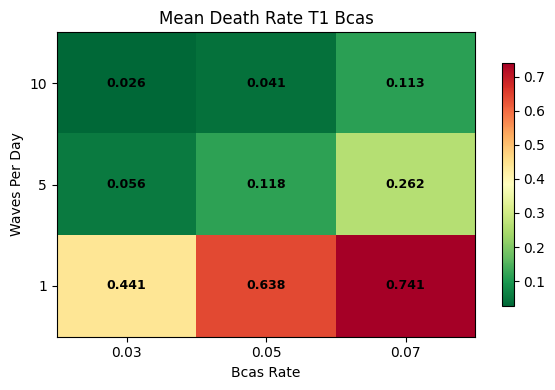

In [15]:
UNCERTAINTY_2 = "bcas_rate"  # set to None to skip heatmap

if UNCERTAINTY_2 and UNCERTAINTY_2 in df.columns:
    pivot = df.pivot_table(values=OUTCOME, index=UNCERTAINTY, columns=UNCERTAINTY_2, aggfunc="mean")
    pivot = pivot.sort_index(ascending=False)

    fig, ax = plt.subplots(figsize=(max(6, len(pivot.columns) * 1.2), max(4, len(pivot) * 0.8)))
    im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn_r")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels([str(c) for c in pivot.columns])
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels([str(i) for i in pivot.index])
    ax.set_xlabel(UNCERTAINTY_2.replace("_", " ").title())
    ax.set_ylabel(uncertainty_label)
    ax.set_title(f"Mean {outcome_label}")

    # Annotate cells
    for i in range(len(pivot.index)):
        for j in range(len(pivot.columns)):
            val = pivot.values[i, j]
            if not np.isnan(val):
                ax.text(j, i, f"{val:.3f}", ha="center", va="center", fontsize=9, fontweight="bold")

    fig.colorbar(im, ax=ax, shrink=0.8)
    plt.tight_layout()
    plt.show()
else:
    print("Set UNCERTAINTY_2 to a valid column name to see the heatmap.")